# Aula 1 – Machine Learning Aplicada à Indústria
## Notebook do Aluno

**Nome:** ARTHUR MINORU MAEZONO
**Data:** 17/10/2026  

### Objetivo da aula
- compreender o problema industrial;
- ler a base de dados;
- identificar faltantes, duplicatas e possíveis outliers;
- registrar observações que serão usadas no pré-processamento.


## 1. Importação das bibliotecas

Complete a célula abaixo com as bibliotecas que serão usadas.


In [ ]:
# Complete:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Leitura da base

Complete com o nome do arquivo e carregue o dataset.


In [ ]:
# Complete:
arquivo = pd.read_csv('/content/dados_aula1_machine_learning_industria.csv')

df = arquivo
# visualizar dimensões da base
# df.head()
# df.shape
# df.info()
# df.describe().T
df.isna().astype(int).sum().sort_values(ascending=False)
# df.isnull()

,0
vazao_medida_l_min,12
tempo_resposta_ms,11
pressao_linha_bar,10
temperatura_processo_c,10
ph_produto,8
modo_controle,5
operador,5
setpoint_vazao_l_min,0
status_valvula,0
timestamp,0


## 3. Visualização inicial

Mostre as primeiras linhas da base e registre abaixo o que você percebe.

**Anotações do aluno:**  
Com as primeiras linhas é possível ver quantos registros temos no dataset, nesse caso, 188. O dataframe tem notal de 15 colunas, onde, com base no `Non_Null Count`, nem todos os registros estão preenchidos.


In [ ]:
# Complete para visualizar as primeiras linhas
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188 entries, 0 to 187
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   timestamp                188 non-null    object 
 1   lote_producao            188 non-null    object 
 2   operador                 183 non-null    object 
 3   modo_controle            183 non-null    object 
 4   status_valvula           188 non-null    object 
 5   setpoint_vazao_l_min     188 non-null    float64
 6   vazao_medida_l_min       176 non-null    float64
 7   pressao_linha_bar        178 non-null    float64
 8   temperatura_processo_c   178 non-null    float64
 9   abertura_valvula_pct     188 non-null    float64
 10  vibracao_bomba_mm_s      188 non-null    float64
 11  tempo_resposta_ms        177 non-null    float64
 12  ph_produto               180 non-null    float64
 13  densidade_produto_g_cm3  188 non-null    float64
 14  status_instrumentacao    1

## 4. Tipos de dados

Verifique os tipos das colunas e descreva quais são numéricas e quais são categóricas.

**Anotações do aluno:**  
- Colunas numéricas: setpoint_vazao_l_min, vazao_medida_l_min, pressao_linha_bar, temperatura_processo_c, abertura_valvula_pct, vibracao_bomba_mm_s, tempo_resposta_ms, ph_produto e densidade_produto_g_cm3.
- Colunas categóricas: timestamp, lote_producao, operador, modo_controle, status_valvula e status_instrumentacao  


In [ ]:
# Complete para exibir informações gerais da base
df.describe(include=[np.number]).T

,count,mean,std,min,25%,50%,75%,max
setpoint_vazao_l_min,188.0,119.056277,12.164116,90.340,110.3375,119.2300,126.9200,156.950
vazao_medida_l_min,176.0,119.571761,13.808622,90.230,110.2875,118.5650,128.7800,160.330
pressao_linha_bar,178.0,3.954781,0.842332,2.811,3.5655,3.8865,4.1190,10.200
temperatura_processo_c,178.0,43.874213,9.399248,26.070,40.0275,43.1750,46.6650,110.000
abertura_valvula_pct,188.0,58.468617,16.380992,18.010,46.7575,58.6000,67.7500,99.280
vibracao_bomba_mm_s,188.0,2.336059,0.958364,0.386,1.7935,2.2900,2.7210,9.100
tempo_resposta_ms,177.0,337.286441,129.197193,130.100,278.2000,321.4000,377.5000,1500.000
ph_produto,180.0,6.806500,0.312416,6.040,6.6100,6.8200,7.0125,7.560
densidade_produto_g_cm3,188.0,1.040255,0.030946,0.949,1.0210,1.0395,1.0620,1.134


## 5. Estatísticas descritivas

Gere estatísticas descritivas das variáveis numéricas.


In [ ]:
# Complete
print(df.isna().astype(int).sum().sort_values(ascending=False))

vazao_medida_l_min         12
tempo_resposta_ms          11
pressao_linha_bar          10
temperatura_processo_c     10
ph_produto                  8
modo_controle               5
operador                    5
setpoint_vazao_l_min        0
status_valvula              0
timestamp                   0
lote_producao               0
vibracao_bomba_mm_s         0
abertura_valvula_pct        0
densidade_produto_g_cm3     0
status_instrumentacao       0
dtype: int64


## 6. Valores faltantes

Descubra quantos valores faltantes existem por coluna.

**Pergunta:** quais colunas parecem exigir maior atenção?


In [ ]:
# Complete
df.isnull().sum()

,0
timestamp,0
lote_producao,0
operador,5
modo_controle,5
status_valvula,0
setpoint_vazao_l_min,0
vazao_medida_l_min,12
pressao_linha_bar,10
temperatura_processo_c,10
abertura_valvula_pct,0


**Resposta do aluno:**  
As colunas que exigem atenção são: operador, modo_controle, vazao_medida_l_min, pressao_linha_bar, temperatura_processo_c, tempo_resposta_ms, ph_produto.<br>
Todas essas informações faltantes são informações importantes, a falta delas pode indicar alguma falha.


## 7. Duplicatas

Verifique se existem linhas duplicadas.


In [ ]:

df.duplicated().sum()

np.int64(8)

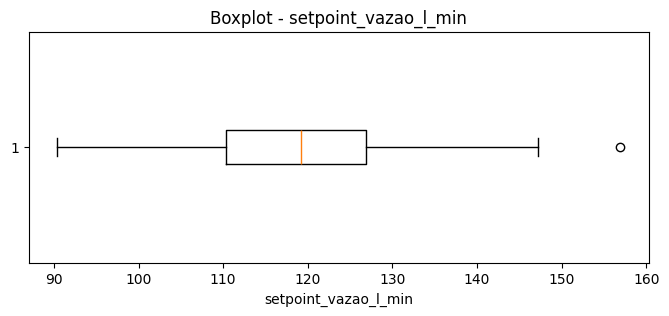

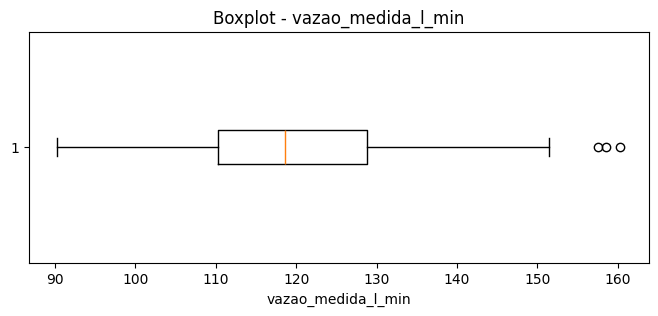

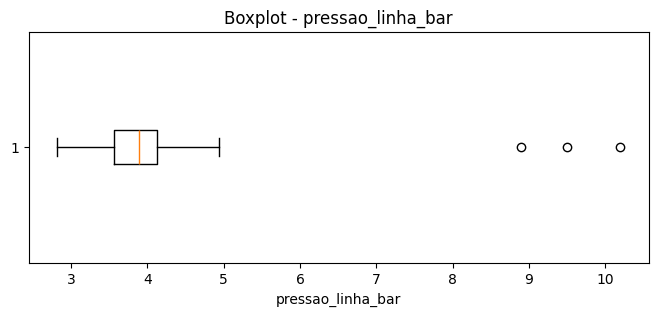

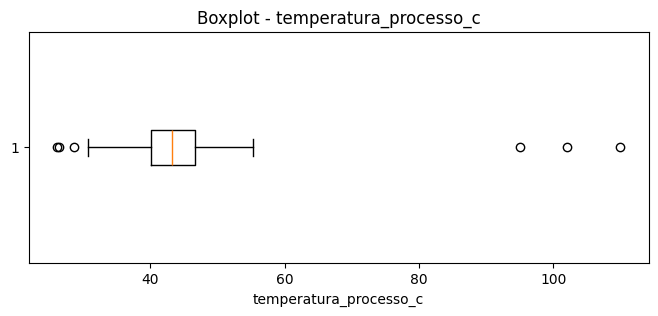

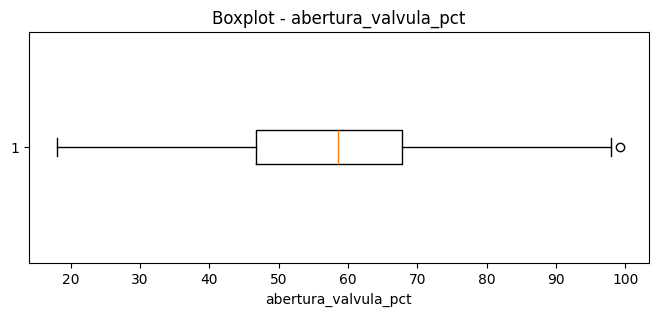

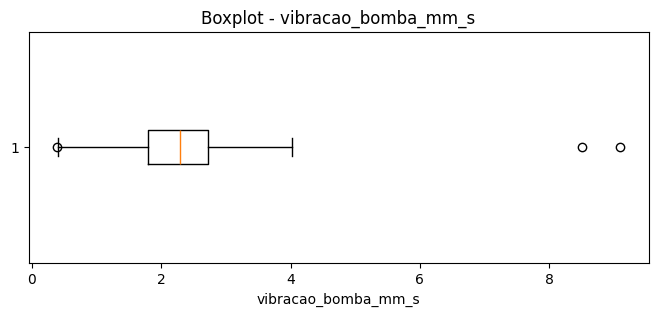

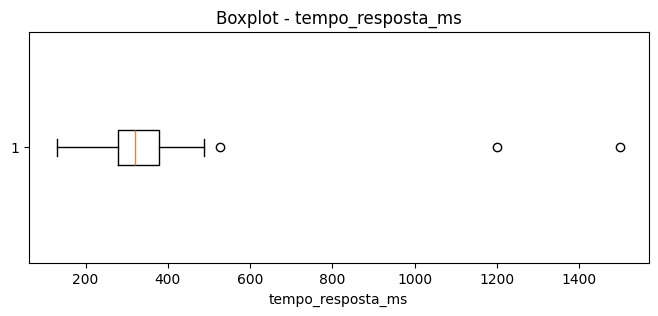

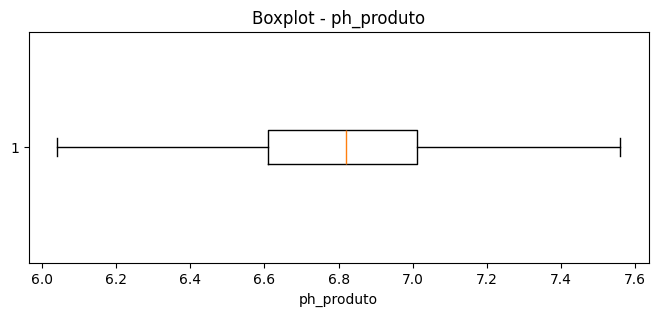

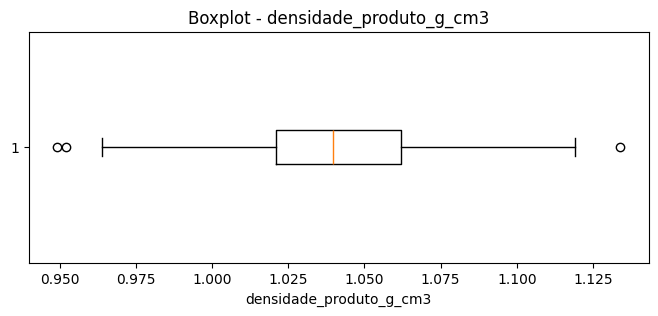

In [ ]:
# Complete
# Definir lista de variáveis numéricas para análise
colunas_numericas = [
'setpoint_vazao_l_min',
'vazao_medida_l_min',
'pressao_linha_bar',
'temperatura_processo_c',
'abertura_valvula_pct',
'vibracao_bomba_mm_s',
'tempo_resposta_ms',
'ph_produto',
'densidade_produto_g_cm3'
]
# Gerar boxplot para cada variável numérica
for coluna in colunas_numericas:
  plt.figure(figsize=(8, 3))
  plt.boxplot(df[coluna].dropna(), vert=False) # horizontal para melhor leitura
  plt.title(f'Boxplot - {coluna}')
  plt.xlabel(coluna)
  plt.show()

**Resposta do aluno:**  
Quantidade de duplicatas encontradas: 61 no dataframe inteiro.


## 8. Busca inicial por outliers

Escolha algumas colunas numéricas importantes e gere boxplots.
Sugestão:
- pressao_linha_bar
- temperatura_processo_c
- vibracao_bomba_mm_s
- tempo_resposta_ms


In [ ]:
ex_outliers = ['pressao_linha_bar', 'temperatura_processo_c', 'vibracao_bomba_mm_s', 'tempo_resposta_ms']

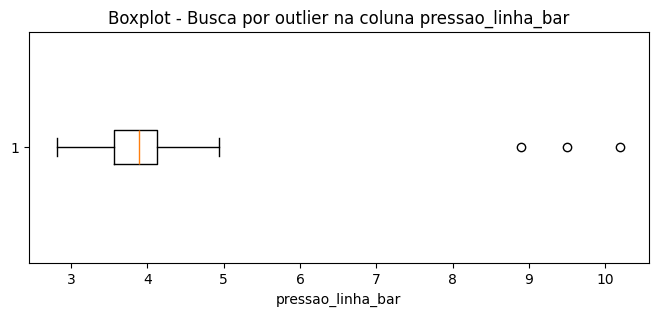

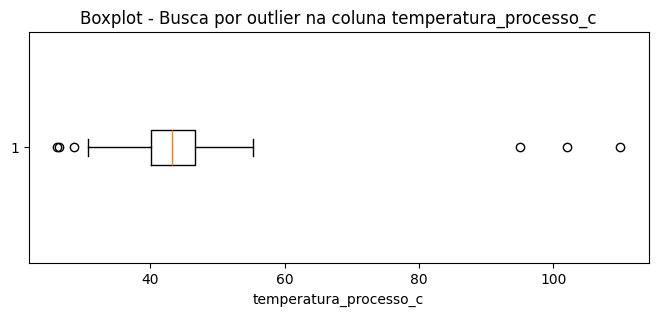

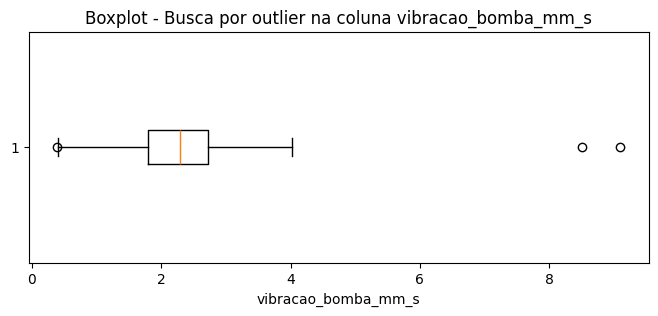

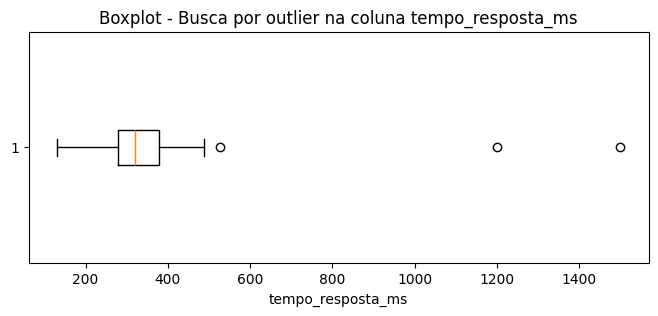

In [ ]:
# Complete
# dica: crie uma lista com as colunas e use um laço para gerar os gráficos
for outlier in ex_outliers:
  plt.figure(figsize = (8, 3))
  plt.boxplot(df[outlier].dropna(), vert = False)
  plt.title(f"Boxplot - Busca por outlier na coluna {outlier}")
  plt.xlabel(outlier)
  plt.show()


**Anotações do aluno sobre possíveis outliers:**  
Foi usado como base para análise as colunas sugeridas no enunciado, nelas, todas apresentam outliers.


## 9. Correlação entre variáveis numéricas

Calcule a matriz de correlação.


In [ ]:
# Complete
df[ex_outliers].corr()

,pressao_linha_bar,temperatura_processo_c,vibracao_bomba_mm_s,tempo_resposta_ms
pressao_linha_bar,1.000000,-0.040471,-0.004311,-0.034882
temperatura_processo_c,-0.040471,1.000000,0.057550,-0.016420
vibracao_bomba_mm_s,-0.004311,0.057550,1.000000,-0.064778
tempo_resposta_ms,-0.034882,-0.016420,-0.064778,1.000000


## 10. Criação de uma variável auxiliar

Crie uma variável com o desvio absoluto entre:
- setpoint_vazao_l_min
- vazao_medida_l_min

Nome sugerido: `desvio_vazao_abs`


In [ ]:
# Complete
df['desvio_vazao_abs'] = (df['setpoint_vazao_l_min'] - df['vazao_medida_l_min']).abs()

In [ ]:
df['desvio_vazao_abs'].describe()

,desvio_vazao_abs
count,176.000000
mean,6.539773
std,5.079625
min,0.110000
25%,2.405000
50%,5.660000
75%,9.825000
max,21.580000


## 11. Interpretação técnica

Responda com base na exploração realizada:

1. Quais problemas de qualidade de dados foram identificados?
Nem todos os registros estão completos, indicando uma possível falha na hora de captar esses dados.
____________________________________________________________

2. Quais variáveis parecem críticas para avaliar a instrumentação?  
vazao_medida_l_min, tempo_resposta_ms, pressao_linha_bar, temperatura_processo_c, ph_produto, modo_controle e operador, por terem informações faltando nos registros.
pressao_linha_bar, temperatura_processo_c, vibracao_bomba_mm_s e tempo_resposta_ms por terem registros que estão muito mais altos que o normal.
____________________________________________________________

3. Por que não devemos treinar um modelo imediatamente, sem inspeção?
Muitas vezes os datasets não vem devidamente tratados, possuindo duplicatas ou não tendo observações que seriam importantes para o Machine Learning, treinar eles sem o devido tratamento pode gerar não tão preciso quanto se estivesse devidamente tratado.
____________________________________________________________


## 12. Fechamento

Nesta aula, você começou a trabalhar o início do pipeline de Machine Learning:
- definição do problema;
- conhecimento da base;
- análise exploratória;
- identificação de problemas de qualidade.

Na próxima etapa, a base poderá ser tratada para uso em modelagem.
